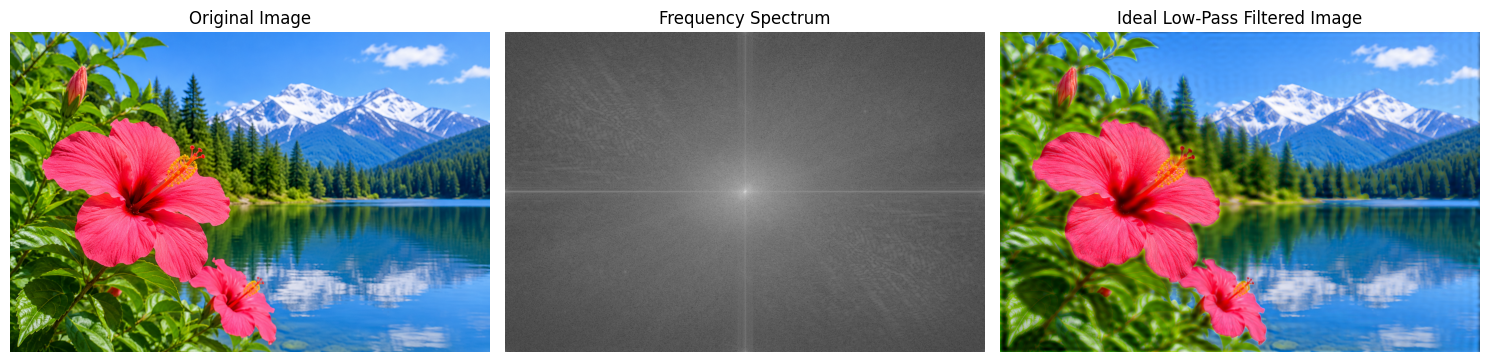

Ideal Low-Pass Filtering Completed Successfully!


In [1]:
# Ideal Low-Pass Filter (ILPF)
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("image.jpg")

if image is None:
    raise FileNotFoundError("Image not found!")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

H, S, I = cv2.split(hsv_image)

dft = np.fft.fft2(I)
dft_shift = np.fft.fftshift(dft)

rows, cols = I.shape
crow, ccol = rows // 2, cols // 2

D0 = 50

mask = np.zeros((rows, cols), np.float32)

for u in range(rows):
    for v in range(cols):
        D = np.sqrt((u - crow)**2 + (v - ccol)**2)

        if D <= D0:
            mask[u, v] = 1

filtered_dft = dft_shift * mask

idft_shift = np.fft.ifftshift(filtered_dft)
idft = np.fft.ifft2(idft_shift)

filtered_I = np.abs(idft)
filtered_I = np.clip(filtered_I, 0, 255).astype(np.uint8)

filtered_hsv = cv2.merge((H, S, filtered_I))

filtered_image = cv2.cvtColor(
    filtered_hsv, cv2.COLOR_HSV2RGB
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(dft_shift)), cmap="gray")
plt.title("Frequency Spectrum")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(filtered_image)
plt.title("Ideal Low-Pass Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "ILPF_filtered_image.jpg",
    cv2.cvtColor(filtered_image, cv2.COLOR_RGB2BGR)
)

print("Ideal Low-Pass Filtering Completed Successfully!")
